# Obrada i analiza ADS-B podataka: određivanje faza leta

**Skup podataka:** OpenSky ADS-B *state vectors*, 7. avgust 2017, 24 sata.
**Analizirane veličine:** barometarska visina (`baroaltitude`), brzina nad zemljom (`velocity`), vertikalna brzina (`vertrate`).

## Sažetak

Cilj rada je određivanje faza leta (poletanje, uspon, krstarenje, spuštanje, sletanje) iz realnih ADS-B podataka. Sirovi podaci su neravnomerno uzorkovani, sadrže duplikate, praznine i impulsne ispade, pa težište rada leži na **obradi podataka**: uklanjanju duplikata, despajkovanju (nelinearni median filtar), resemplovanju na ravnomernu mrežu i izdvajanju isključivo **potpunih letova zadovoljavajućeg kvaliteta**. Nad očišćenim signalima sprovodi se spektralna analiza, projektuju se i brojčano porede tri niskopropusna filtra (Butterworth, Chebyshev I, FIR), a faze leta se određuju pragovima nad filtriranim signalima.

## 1. Podaci i izdvajanje letova

ADS-B *state vector* sadrži periodičan izveštaj aviona (na približno 10 s) o poziciji, visini i brzinama. Za analizu se koristi javni OpenSky uzorak za ceo dan (24 časovne arhive).

**Postupak izdvajanja letova:**

1. Redovi svih 24 sata se spajaju i sortiraju po avionu (`icao24`) i vremenu; duplikati na istom vremenskom trenutku se uklanjaju.
2. Zapis se deli na pojedinačne letove na (a) promeni aviona, (b) vremenskoj rupi dužoj od 20 min, ili (c) sletanju nakon kojeg sledi novo poletanje (zemaljska pauza).
3. Zadržavaju se samo **potpuni letovi** — oni kod kojih se u zapisu vide i poletanje i sletanje. Potpunost se utvrđuje iz profila visine, bez apsolutnih pragova: oba kraja zapisa moraju biti blizu sopstvenog minimuma visine (tlo), uspon mora biti značajan, a sredina leta mora ostati u vazduhu (jedan let, a ne više slepljenih nogu).
4. Dodatno se odbacuju letovi **lošeg kvaliteta**: oni sa prevelikom rupom u zapisu ili sa previše nedostajućih odbiraka (pokrivenost ispod 80%), jer bi interpolacija preko velikih praznina iskrivila analizu.

Rezultat se kešira (`data/flights_catalog.csv` i `data/cache/*.npy`) i gradi se samo pri prvom pokretanju.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import gzip, tarfile, urllib.request, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import ipywidgets as widgets
from IPython.display import display

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})


def rmse(reference, estimate):
    """Koren srednje kvadratne greske."""
    return np.sqrt(np.mean((reference - estimate) ** 2))
np.random.seed(12345)

DATE = "2017-08-07"
DATA_DIR = Path("data")
CATALOG_PATH = DATA_DIR / "flights_catalog.csv"
CACHE_DIR = DATA_DIR / "cache"
URL = ("https://s3.opensky-network.org/data-samples/states/"
       ".{date}/{h:02d}/states_{date}-{h:02d}.csv.tar")
REQUIRED = ["baroaltitude", "velocity", "vertrate"]
NUM_COLS = ["lat", "lon", "velocity", "vertrate", "baroaltitude"]

# Parametri izdvajanja i kontrole kvaliteta letova
DT = 10              # perioda uzorkovanja ciljne mreze [s]
GAP = 1200           # rupa veca od 20 min -> prekid zapisa
MIN_GROUND = 300     # zemaljska pauza >= 5 min -> granica izmedju letova
MARGIN = 500.0       # "uz tlo": kraj leta unutar ovoliko od sopstvenog minimuma [m]
CLIMB = 3000.0       # minimalni uspon da bi let bio realan [m]
MID_UP = 2000.0      # sredina leta mora ostati iznad min + ovoliko [m]
MAX_GAP = 600        # najveca dozvoljena rupa u zapisu [s]
MIN_COVERAGE = 0.80  # najmanja dozvoljena pokrivenost (1 - udeo nedostajucih odbiraka)

# Standardne devijacije sintetickog suma za poredjenje filtara (isti za sve filtre).
# Visina: nesigurnost barometarske visine je reda desetina metara (ne samo
# kvantizacija 25 ft = 7.62 m); brzina i vert. brzina su preciznije.
NOISE_STD = {"baroaltitude": 25.0, "velocity": 1.0, "vertrate": 0.5}

# Najveca fizicki moguca promena izmedju dva odbirka (10 s); veci skok od OBA
# suseda je nefizicki -> izolovani impulsni ispad.
MAX_STEP = {"baroaltitude": 600.0, "velocity": 50.0, "vertrate": 20.0}


def build_database():
    """Preuzima 24 sata, izdvaja potpune letove zadovoljavajuceg kvaliteta i kesira ih."""
    DATA_DIR.mkdir(exist_ok=True)

    def read_hour(h):
        tarp = DATA_DIR / f"states_{DATE}-{h:02d}.csv.tar"
        if not tarp.exists():
            print(f"  preuzimanje sata {h:02d} ...")
            urllib.request.urlretrieve(URL.format(date=DATE, h=h), tarp)
        with tarfile.open(tarp) as tar:
            f = tar.extractfile(f"states_{DATE}-{h:02d}.csv.gz")
            df = pd.read_csv(gzip.open(f),
                             usecols=["time", "icao24", "callsign", "onground"] + NUM_COLS)
        return df.dropna(subset=REQUIRED)

    print("Izgradnja baze letova iz 24 sata (jednokratno, ~2-3 min) ...")
    big = pd.concat([read_hour(h) for h in range(24)], ignore_index=True)
    big = (big.sort_values(["icao24", "time"])
              .drop_duplicates(["icao24", "time"], keep="last").reset_index(drop=True))

    # Granice letova: drugi avion, rupa > GAP, ili sredina duze zemaljske pauze
    t = big["time"].to_numpy(); ic = big["icao24"].to_numpy()
    alt = big["baroaltitude"].to_numpy(); vel = big["velocity"].to_numpy()
    og = big["onground"]
    og = (og.astype(str).str.lower() == "true").to_numpy() if og.dtype == object else og.to_numpy(bool)
    grounded = og | ((alt < 200) & (vel < 40))
    new_track = np.r_[True, ic[1:] != ic[:-1]] | (np.r_[np.inf, np.diff(t)] > GAP)
    track = np.cumsum(new_track)
    chg = np.r_[True, grounded[1:] != grounded[:-1]] | new_track
    st = np.flatnonzero(chg); en = np.r_[st[1:], len(grounded)]; dur = t[en - 1] - t[st]
    mids = np.array([(s + e) // 2 for s, e, gg, du in zip(st, en, grounded[st], dur)
                     if gg and du >= MIN_GROUND and e - s >= 2], dtype=int)
    breaks = new_track.copy()
    if len(mids):
        breaks[mids[track[mids] == track[mids - 1]]] = True
    big["flight_id"] = np.cumsum(breaks)

    # Despajkovana visina (klizna medijana) -> robustna procena tla i ekstrema
    big["alt_med"] = (big.groupby("flight_id")["baroaltitude"]
                      .rolling(5, center=True, min_periods=1).median().reset_index(level=0, drop=True))

    def callsign_of(s):
        s = s.dropna().astype(str).str.strip(); s = s[s != ""]
        return s.mode().iloc[0] if len(s) else ""

    g = big.groupby("flight_id", sort=True)
    cat = pd.DataFrame({
        "icao24": g["icao24"].first(), "callsign": g["callsign"].apply(callsign_of),
        "n": g.size(), "t0": g["time"].first(), "t1": g["time"].last(),
        "alt_min": g["alt_med"].min(), "alt_max": g["alt_med"].max(),
        "a0": g["alt_med"].first(), "a1": g["alt_med"].last(),
    }).reset_index()
    cat["dur_min"] = ((cat.t1 - cat.t0) / 60).round(1)

    # Minimum visine na srednjih 15-85% leta (otkriva sletanje usred zapisa)
    pos = big.groupby("flight_id").cumcount()
    grpn = big.groupby("flight_id")["flight_id"].transform("size")
    frac = pos / (grpn - 1).clip(lower=1)
    cat["midmin"] = cat.flight_id.map(big[(frac >= 0.15) & (frac <= 0.85)].groupby("flight_id")["alt_med"].min())
    # Mere kvaliteta: najveca rupa i pokrivenost
    cat["max_gap"] = cat.flight_id.map(big.assign(_d=big.groupby("flight_id")["time"].diff()).groupby("flight_id")["_d"].max())
    cat["coverage"] = cat.n / ((cat.t1 - cat.t0) / DT + 1)

    complete = ((cat.a0 - cat.alt_min < MARGIN) & (cat.a1 - cat.alt_min < MARGIN) &
                (cat.alt_max - cat.alt_min > CLIMB) & (cat.midmin > cat.alt_min + MID_UP) &
                (cat.n >= 60))
    good = complete & (cat.max_gap <= MAX_GAP) & (cat.coverage >= MIN_COVERAGE)
    cat = cat[good].copy()

    big = big[big.flight_id.isin(set(cat.flight_id))].sort_values(["flight_id", "time"]).reset_index(drop=True)
    sizes = big.groupby("flight_id", sort=True).size()
    cat["row_start"] = cat.flight_id.map(dict(zip(sizes.index, np.r_[0, np.cumsum(sizes.values)[:-1]]))).astype("int64")
    for c in ["alt_min", "alt_max"]:
        cat[c] = cat[c].round(0)
    cat["max_gap"] = cat.max_gap.fillna(0).round(0)
    cat["coverage"] = cat.coverage.round(3)

    # Prvo kes (.npy), pa katalog: ako upis kesa padne, katalog ne ostane neuskladjen
    CACHE_DIR.mkdir(exist_ok=True)
    np.save(CACHE_DIR / "time.npy", big["time"].to_numpy("int32"))
    for c in NUM_COLS:
        np.save(CACHE_DIR / f"{c}.npy", big[c].to_numpy("float32"))
    og = big["onground"]
    og = (og.astype(str).str.lower() == "true").to_numpy() if og.dtype == object else og.to_numpy(bool)
    np.save(CACHE_DIR / "onground.npy", og)
    (cat.drop(columns=["a0", "a1", "midmin"]).sort_values("dur_min", ascending=False)
        .to_csv(CATALOG_PATH, index=False))
    print(f"Kesirano {len(cat)} potpunih letova zadovoljavajuceg kvaliteta.")


if not (CATALOG_PATH.exists() and (CACHE_DIR / "time.npy").exists()):
    build_database()

CATALOG = pd.read_csv(CATALOG_PATH).sort_values("dur_min", ascending=False).reset_index(drop=True)
# Kolone se ucitavaju cele u memoriju (kes je mali, ~45 MB); jedan let je opseg redova.
COLS = {c: np.load(CACHE_DIR / f"{c}.npy") for c in ["time"] + NUM_COLS + ["onground"]}
print(f"Katalog: {len(CATALOG)} potpunih letova ({DATE}).")
print(f"Trajanje [min]: min {CATALOG.dur_min.min():.0f}, medijana {CATALOG.dur_min.median():.0f}, "
      f"max {CATALOG.dur_min.max():.0f}. Medijana pokrivenosti: {CATALOG.coverage.median():.0%}.")


def flight_label(r):
    name = r.callsign if isinstance(r.callsign, str) and r.callsign.strip() else r.icao24
    return f"{name:<8} {r.dur_min:6.0f} min  {int(r.n):>4} odb  pokr {r.coverage:.0%}  ({int(r.alt_max)} m)"

# Podrazumevani let: srednje trajanje (60-180 min), sa callsign-om, najbolja pokrivenost
mid = CATALOG[CATALOG.dur_min.between(60, 180) & CATALOG.callsign.notna()]
default_id = int((mid if len(mid) else CATALOG).sort_values("coverage", ascending=False).iloc[0].flight_id)
flight_selector = widgets.Dropdown(
    options=[(flight_label(r), int(r.flight_id)) for r in CATALOG.itertuples()],
    value=default_id, description="Let:", layout=widgets.Layout(width="640px"),
    style={"description_width": "initial"})
display(flight_selector)

### Učitavanje i priprema izabranog leta

Sirovi signali se najpre **despajkuju** (uklanjaju se izolovani impulsni ispadi nelinearnim despike-om; obrazloženje u odeljku 3.4), a zatim **resempluju na ravnomernu mrežu od 10 s**. Ravnomerno uzorkovanje je preduslov za FFT i digitalne filtre, koji su definisani samo za konstantan korak. Pozicija (`lat`/`lon`) se interpolira posebno jer ume da nedostaje.

In [ ]:
fid = int(flight_selector.value)
row = CATALOG[CATALOG.flight_id == fid].iloc[0]
ICAO24 = row.icao24
CALLSIGN = row.callsign if isinstance(row.callsign, str) and row.callsign.strip() else ICAO24
s, n = int(row.row_start), int(row.n)

timestamps_raw = np.asarray(COLS["time"][s:s + n], float)
column = lambda c: np.asarray(COLS[c][s:s + n], float)
altitude_native = column("baroaltitude")
velocity_native = column("velocity")
vertrate_native = column("vertrate")
lat_native = column("lat")
lon_native = column("lon")
onground_native = np.asarray(COLS["onground"][s:s + n], bool)


def despike(x, max_step):
    """Uklanja IZOLOVANE impulsne ispade (skok-i-povratak u jednom odbirku).

    Uzorak je ispad ako od OBA suseda odstupa vise od max_step (sto bi znacilo
    nefizicku promenu izmedju dva odbirka na 10 s) i zamenjuje se prosekom
    suseda. Monotone realne promene (uspon, spustanje, sletanje) blizu su bar
    jednog suseda, pa se NE diraju (nema laznih ispravki na manevrima/krajevima).
    """
    x = np.asarray(x, float)
    n = len(x)
    out = x.copy()
    mask = np.zeros(n, bool)
    if n >= 3:
        d_prev = np.abs(x[1:-1] - x[:-2])
        d_next = np.abs(x[1:-1] - x[2:])
        isolated = np.minimum(d_prev, d_next) > max_step
        idx = np.flatnonzero(isolated) + 1
        out[idx] = 0.5 * (x[idx - 1] + x[idx + 1])
        mask[idx] = True
    return out, mask


altitude_clean, alt_spikes = despike(altitude_native, MAX_STEP["baroaltitude"])
velocity_clean, _ = despike(velocity_native, MAX_STEP["velocity"])
vertrate_clean, _ = despike(vertrate_native, MAX_STEP["vertrate"])

# Resemplovanje na ravnomernu mrezu; gornja granica +1 da interp ne ekstrapolira
timestamps = np.arange(timestamps_raw[0], timestamps_raw[-1] + 1, DT)
time_min = (timestamps - timestamps[0]) / 60
fs = 1 / DT

altitude = np.interp(timestamps, timestamps_raw, altitude_clean)
velocity = np.interp(timestamps, timestamps_raw, velocity_clean)
vertrate = np.interp(timestamps, timestamps_raw, vertrate_clean)

def interp_position(x):
    ok = np.isfinite(x)
    if not ok.any():
        return np.full_like(timestamps, np.nan, float)
    return np.interp(timestamps, timestamps_raw[ok], x[ok])
latitude = interp_position(lat_native)
longitude = interp_position(lon_native)
has_position = bool(np.isfinite(latitude).all() and np.isfinite(longitude).all())
onground = np.interp(timestamps, timestamps_raw, onground_native.astype(float)) >= 0.5

start_utc = datetime.fromtimestamp(timestamps[0], tz=timezone.utc)
end_utc = datetime.fromtimestamp(timestamps[-1], tz=timezone.utc)
print(f"Izabrani let: {CALLSIGN} ({ICAO24})")
print(f"Interval: {start_utc:%Y-%m-%d %H:%M:%S} - {end_utc:%H:%M:%S} UTC")
print(f"Trajanje: {(timestamps[-1] - timestamps[0]) / 60:.1f} min")
print(f"Odbiraka (sirovi -> mreza): {len(timestamps_raw)} -> {len(timestamps)}, "
      f"pokrivenost {row.coverage:.0%}, najveca rupa {int(row.max_gap)} s")
print(f"fs = {fs:.3f} Hz, Nyquist = {fs / 2:.3f} Hz")
print(f"Raspon visine: {altitude.min():.0f} - {altitude.max():.0f} m; "
      f"uklonjeno impulsnih ispada u visini: {int(alt_spikes.sum())}")

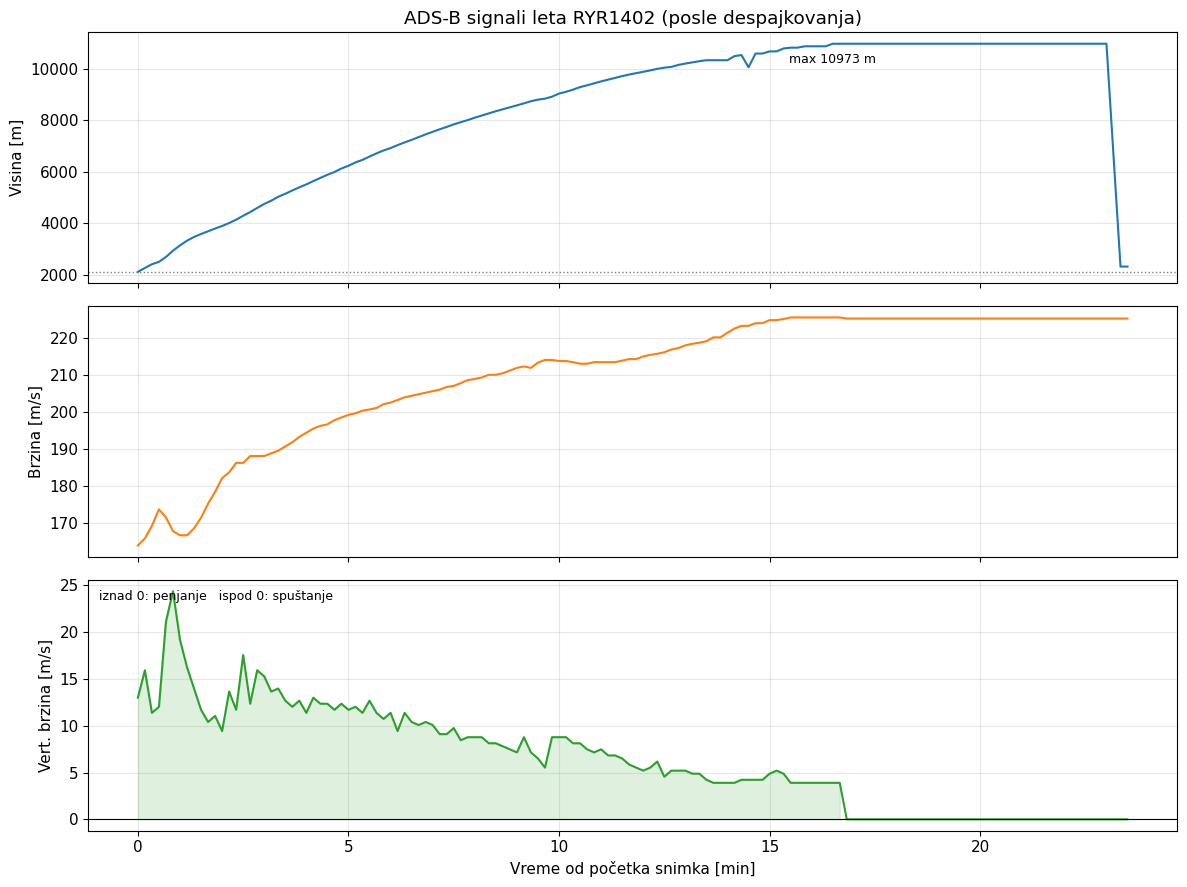

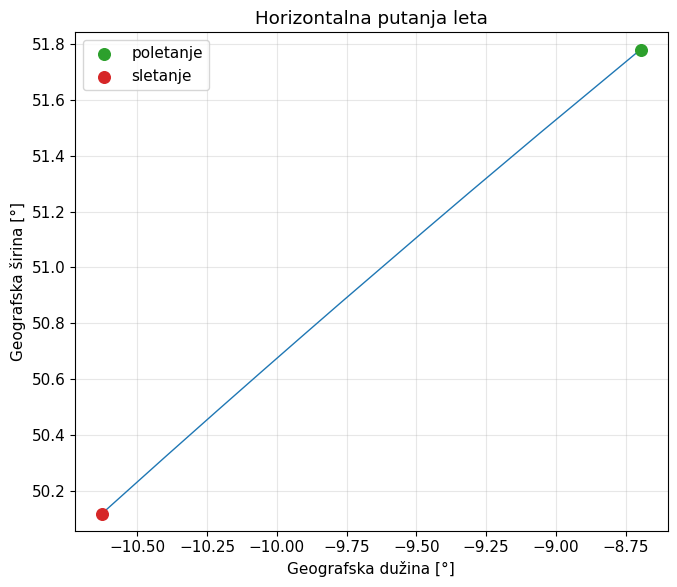

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ground = altitude.min()
axes[0].plot(time_min, altitude, color="tab:blue")
axes[0].axhline(ground, color="gray", ls=":", lw=1)
axes[0].annotate(f"max {altitude.max():.0f} m", xy=(time_min[altitude.argmax()], altitude.max()),
                 xytext=(0, -14), textcoords="offset points", ha="center", fontsize=9)
axes[0].set(ylabel="Visina [m]", title=f"ADS-B signali leta {CALLSIGN} (posle despajkovanja)")
axes[1].plot(time_min, velocity, color="tab:orange")
axes[1].set(ylabel="Brzina [m/s]")
axes[2].plot(time_min, vertrate, color="tab:green")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].fill_between(time_min, 0, vertrate, where=vertrate > 0, color="tab:green", alpha=0.15)
axes[2].fill_between(time_min, 0, vertrate, where=vertrate < 0, color="tab:purple", alpha=0.15)
axes[2].set(xlabel="Vreme od početka snimka [min]", ylabel="Vert. brzina [m/s]")
axes[2].text(0.01, 0.92, "iznad 0: penjanje   ispod 0: spuštanje", transform=axes[2].transAxes, fontsize=9)
plt.tight_layout()
plt.show()

if has_position:
    plt.figure(figsize=(7, 6))
    plt.plot(longitude, latitude, color="tab:blue", lw=1)
    plt.scatter(longitude[0], latitude[0], color="tab:green", s=70, zorder=3, label="poletanje")
    plt.scatter(longitude[-1], latitude[-1], color="tab:red", s=70, zorder=3, label="sletanje")
    plt.xlabel("Geografska dužina [°]"); plt.ylabel("Geografska širina [°]")
    plt.title("Horizontalna putanja leta")
    plt.legend(); plt.axis("equal"); plt.tight_layout(); plt.show()
else:
    print("Let nema ADS-B poziciju (lat/lon) -> horizontalna putanja se preskače.")

Visina pokazuje dugoročni oblik leta (uspon, plato krstarenja, spuštanje). Vertikalna brzina najdirektnije razdvaja penjanje (pozitivna) od spuštanja (negativna), ali sadrži sitne oscilacije oko nule. Brzina nad zemljom pomaže da se nisko letenje razlikuje od kretanja po tlu. Određivanje faze zato kombinuje sve tri veličine, a ne oslanja se na jednu.

## 2. Spektralna analiza i model šuma

### 2.1 Sadržaj signala u frekvencijskom domenu

Posmatrane veličine menjaju se sporo (tokom više minuta), pa je korisna energija koncentrisana na vrlo niskim frekvencijama. Brze promene između susednih odbiraka su uglavnom šum i merne nepreciznosti. Spektar se računa uz Hann prozor radi smanjenja curenja, a uz svaki spektar prikazuje se i kumulativna energija, koja brojčano pokazuje ispod koje frekvencije leži najveći deo energije signala.

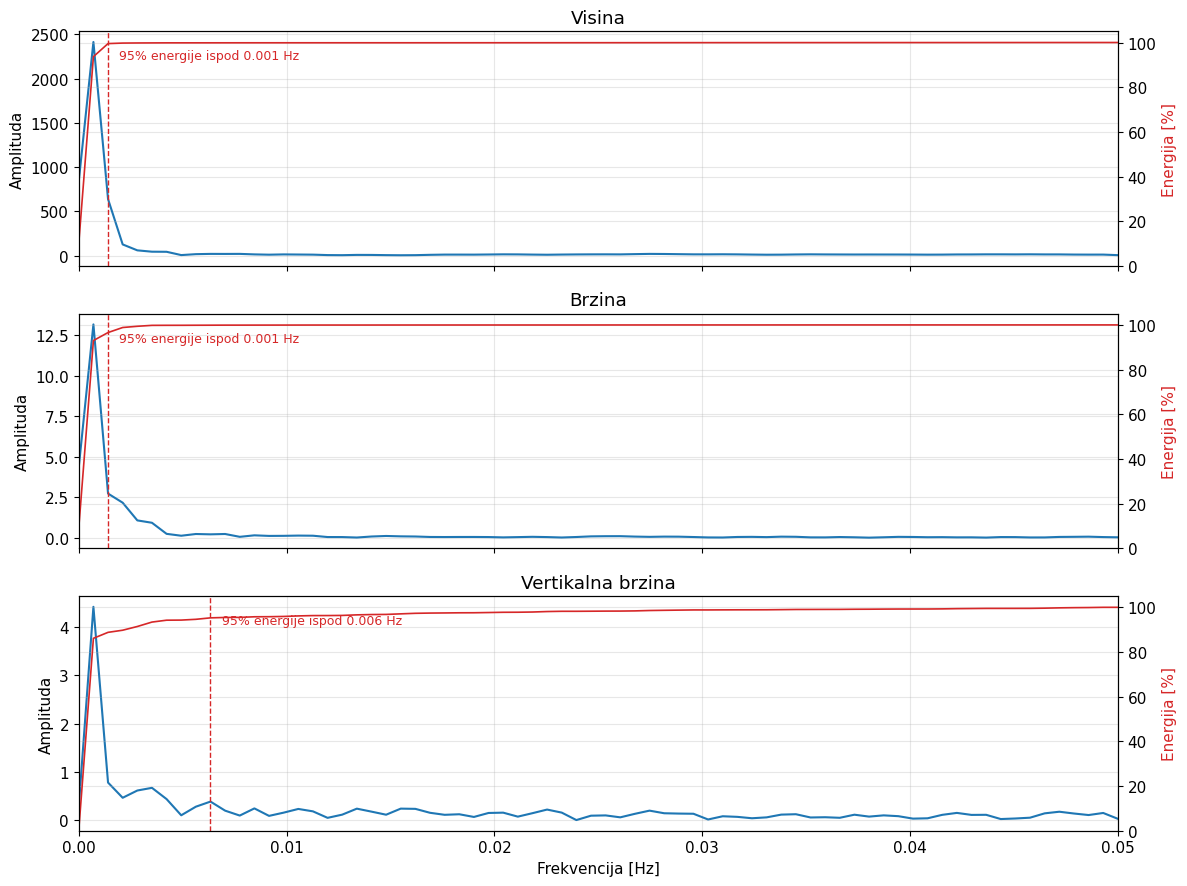

In [17]:
def one_sided_spectrum(x, fs):
    """Jednostrani amplitudski spektar uz Hann prozor (deljenje sa sum(w) cuva amplitudu)."""
    x = x - x.mean()
    n = len(x)
    w = np.hanning(n)
    amp = np.abs(np.fft.rfft(x * w)) / w.sum()
    if n % 2 == 0:
        amp[1:-1] *= 2
    else:
        amp[1:] *= 2
    return np.fft.rfftfreq(n, 1 / fs), amp


fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, sig, label in zip(axes, [altitude, velocity, vertrate],
                          ["Visina", "Brzina", "Vertikalna brzina"]):
    freq, amp = one_sided_spectrum(sig, fs)
    energy = np.cumsum(amp ** 2) / np.sum(amp ** 2)
    f95 = freq[np.searchsorted(energy, 0.95)]
    ax.plot(freq, amp, color="tab:blue", label="amplitudski spektar")
    ax2 = ax.twinx()
    ax2.plot(freq, 100 * energy, color="tab:red", lw=1.2, label="kumulativna energija")
    ax2.axvline(f95, color="tab:red", ls="--", lw=1)
    ax2.set_ylim(0, 105); ax2.set_ylabel("Energija [%]", color="tab:red")
    ax2.annotate(f"95% energije ispod {f95:.3f} Hz", xy=(f95, 95),
                 xytext=(8, -4), textcoords="offset points", color="tab:red", fontsize=9)
    ax.set(ylabel="Amplituda", title=label)
axes[-1].set(xlabel="Frekvencija [Hz]", xlim=(0, fs / 2))
plt.tight_layout()
plt.show()

### 2.2 Model šuma za poređenje filtara

Pošto čist referentni signal nije poznat, originalnom (despajkovanom) signalu dodaje se kontrolisan Gausov šum, isti za sva tri filtra i ponovljiv (fiksni *seed*). Tako se filtri mogu objektivno uporediti preko RMSE u odnosu na original. Standardna devijacija šuma je fizički motivisana: barometarska visina ima nesigurnost reda **desetina metara** (σ ≈ 25 m), znatno veću od same kvantizacije (25 ft = 7.62 m), dok su brzina i vertikalna brzina preciznije (σ = 1 i 0.5 m/s). Na visini je dodati šum mali u odnosu na opseg (kilometri), pa se na punoj skali jedva vidi — zato je dat i uvećani isečak. Konačna klasifikacija faza koristi filtrirane originalne podatke, **bez** dodatog šuma.

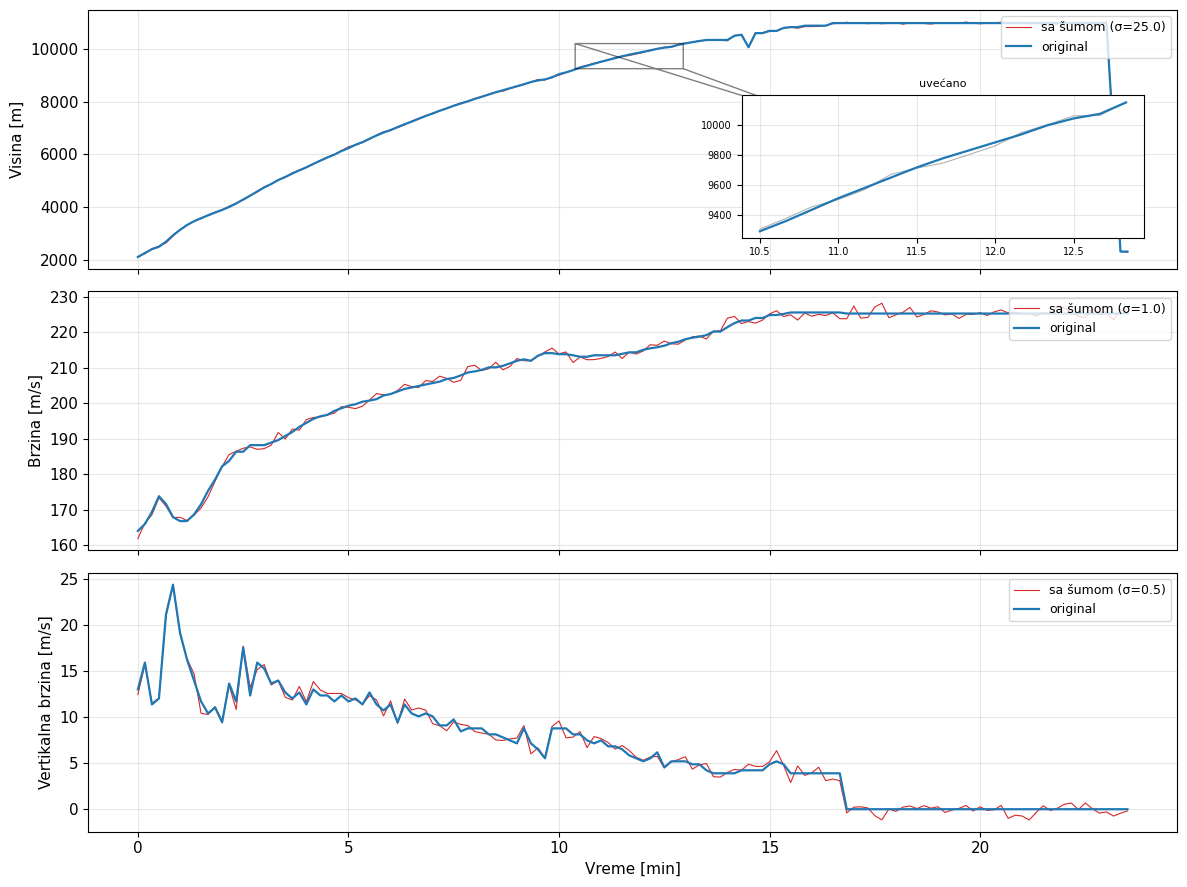

In [ ]:
rng = np.random.default_rng(42)
altitude_test = altitude + rng.normal(0, NOISE_STD["baroaltitude"], len(altitude))
velocity_test = velocity + rng.normal(0, NOISE_STD["velocity"], len(velocity))
vertrate_test = vertrate + rng.normal(0, NOISE_STD["vertrate"], len(vertrate))
sds = [NOISE_STD["baroaltitude"], NOISE_STD["velocity"], NOISE_STD["vertrate"]]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, original, noisy, label, unit, sd in zip(
        axes, [altitude, velocity, vertrate], [altitude_test, velocity_test, vertrate_test],
        ["Visina", "Brzina", "Vertikalna brzina"], ["m", "m/s", "m/s"], sds):
    ax.plot(time_min, noisy, color="tab:red", lw=0.8, label=f"sa šumom (σ={sd})")
    ax.plot(time_min, original, color="tab:blue", lw=1.6, label="original")
    ax.set(ylabel=f"{label} [{unit}]"); ax.legend(loc="upper right", fontsize=9)
# Na visini je sum mali u odnosu na opseg (~km), pa se na punoj skali ne vidi;
# inset uvecava kratak isecak gde se sum jasno vidi.
i0, i1 = int(0.45 * len(time_min)), int(0.55 * len(time_min))
axin = axes[0].inset_axes([0.60, 0.12, 0.37, 0.55])
axin.plot(time_min[i0:i1], altitude_test[i0:i1], color="tab:red", lw=0.8)
axin.plot(time_min[i0:i1], altitude[i0:i1], color="tab:blue", lw=1.6)
axin.set_title("uvećano", fontsize=8); axin.tick_params(labelsize=7); axin.grid(alpha=0.3)
axes[0].indicate_inset_zoom(axin, edgecolor="black")
axes[-1].set_xlabel("Vreme [min]")
plt.tight_layout()
plt.show()

## 3. Projektovanje i poređenje niskopropusnih filtara

### 3.1 Izbor frekvencije odsecanja

Frekvencija odsecanja se ne bira ručno, već kao kompromis *bias–varijansa*: prenisko odsecanje briše realne manevre (sistematska greška), a previsoko propušta šum (varijansa). Traži se odsecanje koje minimizuje rekonstrukcionu RMSE preko reprezentativnog skupa letova; kriva ima plitak minimum, iz kojeg se uzima donja ivica.

In [ ]:
# --- Izbor odsecanja preko bias-varijansa krive ---

def load_grid(fid):
    r = CATALOG[CATALOG.flight_id == fid].iloc[0]
    s, n = int(r.row_start), int(r.n)
    ts = np.asarray(COLS["time"][s:s + n], float)
    gt = np.arange(ts[0], ts[-1] + 1, DT)
    out = {}
    for k in REQUIRED:
        x, _ = despike(np.asarray(COLS[k][s:s + n], float), MAX_STEP[k])
        out[k] = np.interp(gt, ts, x)
    return out

pool = CATALOG[CATALOG.dur_min.between(60, 180)].head(40)["flight_id"].tolist()
grids = [load_grid(f) for f in pool]
rng = np.random.default_rng(0)
noisy = [{k: g[k] + rng.normal(0, NOISE_STD[k], len(g[k])) for k in REQUIRED} for g in grids]

cutoffs = np.array([0.006, 0.008, 0.010, 0.013, 0.016, 0.020, 0.025, 0.030, 0.035])
curve = []
for fc in cutoffs:
    N, W = signal.buttord(fc, min(2.5 * fc, 0.049), 0.5, 20, fs=fs)
    sos = signal.butter(N, W, btype="low", fs=fs, output="sos")
    errs = [sum(np.sqrt(np.mean((g[k] - signal.sosfiltfilt(sos, ng[k])) ** 2)) / NOISE_STD[k]
               for k in REQUIRED) for g, ng in zip(grids, noisy)]
    curve.append(np.median(errs))
curve = np.array(curve)
flat = cutoffs[curve <= curve.min() * 1.03]
CUTOFF = float(flat.min())

plt.figure(figsize=(9, 4))
plt.plot(cutoffs, curve, marker="o", color="tab:blue")
plt.axvspan(flat.min(), flat.max(), color="orange", alpha=0.15, label="plitki optimum (±3%)")
plt.axvline(CUTOFF, color="red", ls="--", label=f"izabrano: {CUTOFF:.3f} Hz")
plt.xlabel("Frekvencija odsecanja [Hz]")
plt.ylabel(f"Medijana normalizovane RMSE\n({len(grids)} letova)")
plt.title("Izbor odsecanja: kompromis bias–varijansa")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Plitki optimum: {flat.min():.3f}-{flat.max():.3f} Hz; izabrano odsecanje {CUTOFF:.3f} Hz.")

# --- Projektovanje filtara iz specifikacije ---
# filtfilt kvadrira amplitudski odziv (i dB se udvostrucuju), pa se prototip
# projektuje na pola dB-skale da efektivni (filtfilt) odziv ispuni specifikaciju.
f_pass, f_stop = CUTOFF, min(2 * CUTOFF, 0.045)
Ap, As = 0.5, 20.0   # prototip; efektivno (posle filtfilt) ~ 1 dB / 40 dB

Nb, Wb = signal.buttord(f_pass, f_stop, Ap, As, fs=fs)
butter_sos = signal.butter(Nb, Wb, btype="low", fs=fs, output="sos")
Nc, Wc = signal.cheb1ord(f_pass, f_stop, Ap, As, fs=fs)
cheby_sos = signal.cheby1(Nc, Ap, Wc, btype="low", fs=fs, output="sos")
numtaps, beta = signal.kaiserord(As, (f_stop - f_pass) / (fs / 2))
numtaps += numtaps % 2 == 0
fir_b = signal.firwin(numtaps, (f_pass + f_stop) / 2, window=("kaiser", beta), fs=fs)
fir_a = np.array([1.0])


def dc_gain(sos):
    return float(np.abs(signal.sosfreqz(sos, worN=[0.0], fs=fs)[1][0]))

# DC pojacanje se normalizuje na 1 (Chebyshev parnog reda ima -Ap dB na 0 Hz)
butter_dc = dc_gain(butter_sos) ** 2
cheby_dc = dc_gain(cheby_sos) ** 2
fir_dc = float(np.abs(fir_b.sum())) ** 2


def apply_lowpass(name, x):
    """Nula-fazno (filtfilt) niskopropusno filtriranje sa DC pojacanjem 1."""
    pad = None if len(x) > 30 else len(x) - 1
    if name == "Butterworth":
        return signal.sosfiltfilt(butter_sos, x, padlen=pad) / butter_dc
    if name == "Chebyshev I":
        return signal.sosfiltfilt(cheby_sos, x, padlen=pad) / cheby_dc
    return signal.filtfilt(fir_b, fir_a, x, padlen=pad) / fir_dc


filters = {"Butterworth": (butter_sos, None), "Chebyshev I": (cheby_sos, None),
           "FIR (Kaiser)": (fir_b, fir_a)}
print(f"Butterworth: red {Nb} (efektivno {2 * Nb}), Wn = {Wb:.4f} Hz")
print(f"Chebyshev I: red {Nc} (efektivno {2 * Nc}), Wn = {Wc:.4f} Hz")
print(f"FIR (Kaiser): {numtaps} tapova, kašnjenje {(numtaps - 1) // 2 * DT} s")

# --- Amplitudski i fazni odziv ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for name, sos in [("Butterworth", butter_sos), ("Chebyshev I", cheby_sos)]:
    f, h = signal.sosfreqz(sos, worN=4096, fs=fs)
    mag = 20 * np.log10(np.maximum(np.abs(h), 1e-8))
    axes[0].plot(f, 2 * mag, label=f"{name} (efektivno, filtfilt)")
f, h = signal.freqz(fir_b, fir_a, worN=4096, fs=fs)
axes[0].plot(f, 2 * 20 * np.log10(np.maximum(np.abs(h), 1e-8)), label="FIR (efektivno)")
axes[0].axvspan(0, f_pass, color="tab:green", alpha=0.08)
axes[0].axvline(f_pass, color="green", ls=":", lw=1, label="propusni rub")
axes[0].axvline(f_stop, color="black", ls=":", lw=1, label="nepropusni rub")
axes[0].axhline(-40, color="gray", lw=0.8)
axes[0].set(ylabel="Pojačanje [dB]", ylim=(-80, 5),
            title="Amplitudski odziv (efektivni, posle filtfilt)")
axes[0].legend(ncol=2, fontsize=8)
for name, (obj, a) in filters.items():
    f, h = signal.sosfreqz(obj, worN=4096, fs=fs) if a is None else signal.freqz(obj, a, worN=4096, fs=fs)
    axes[1].plot(f, np.unwrap(np.angle(h)), label=name)
axes[1].axvline(f_pass, color="green", ls=":", lw=1)
axes[1].set(xlabel="Frekvencija [Hz]", ylabel="Faza [rad]", title="Fazni odziv")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.2 Kašnjenje i način primene

Filtriranje se sprovodi nula-fazno (`filtfilt`, unapred i unazad), čime se poništava fazni pomeraj i signal ostaje vremenski poravnat — granice faza padaju na ispravna vremena. Cena je što takva primena koristi i buduće odbirke, pa nije kauzalna (nije za rad u realnom vremenu). Grafik prikazuje grupno kašnjenje pri *kauzalnoj* primeni svakog filtra.

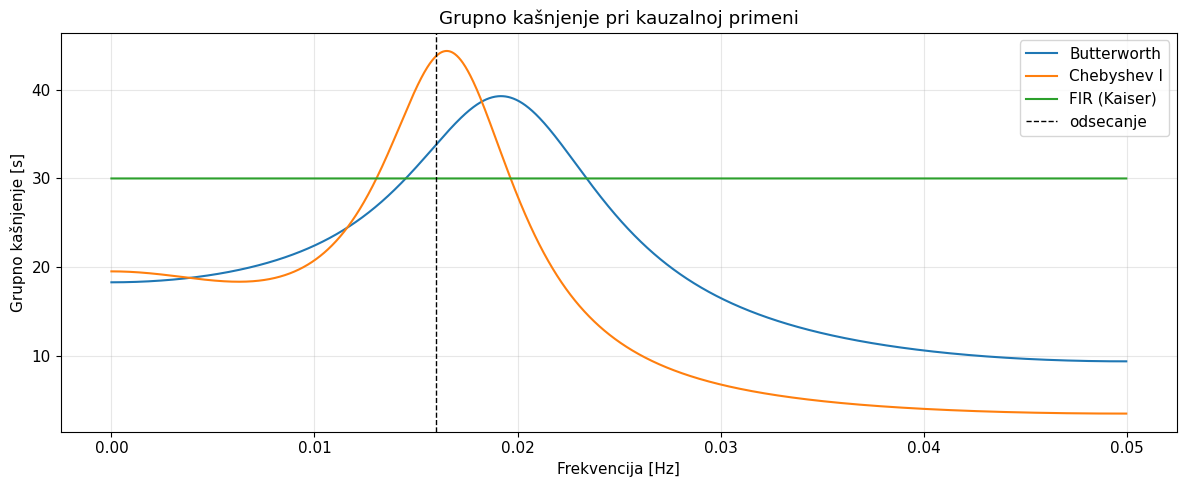

In [7]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, (obj, a) in filters.items():
        b, a_tf = signal.sos2tf(obj) if a is None else (obj, a)
        f, gd = signal.group_delay((b, a_tf), w=2048, fs=fs)
        ok = np.isfinite(gd) & (f <= fs / 2) & (gd >= 0)
        plt.plot(f[ok], gd[ok] * DT, label=name)
plt.axvline(CUTOFF, color="black", ls="--", lw=1, label="odsecanje")
plt.xlabel("Frekvencija [Hz]"); plt.ylabel("Grupno kašnjenje [s]")
plt.title("Grupno kašnjenje pri kauzalnoj primeni")
plt.legend(); plt.tight_layout(); plt.show()

In [8]:
test_signals = {"Visina [m]": (altitude, altitude_test),
                "Brzina [m/s]": (velocity, velocity_test),
                "Vert. brzina [m/s]": (vertrate, vertrate_test)}
print(f"{'Filter':<15}{'Visina RMSE':>13}{'Brzina RMSE':>14}{'Vert.rate RMSE':>16}")
print("-" * 58)
for name in filters:
    vals = [rmse(ref, apply_lowpass(name, noisy_sig)) for ref, noisy_sig in test_signals.values()]
    print(f"{name:<15}{vals[0]:>13.2f}{vals[1]:>14.2f}{vals[2]:>16.2f}")

Filter           Visina RMSE   Brzina RMSE  Vert.rate RMSE
----------------------------------------------------------
Butterworth            15.58          0.70           25.27
Chebyshev I            15.65          0.69           26.92
FIR (Kaiser)           20.17          0.91           26.23


### 3.3 Brojčano poređenje filtara

Pošto se sa grafika razlika teško očitava, filtri se porede i merljivim veličinama: efektivni red (složenost), talasanje u propusnom opsegu (ravnoća), slabljenje u nepropusnom opsegu (potiskivanje šuma), realni −3 dB rub, kauzalno kašnjenje, te performanse na šumu (RMSE i redukcija šuma u dB). Sve vrednosti su efektivne (posle `filtfilt`).

In [ ]:
def mag2(obj, a, f):
    h = signal.sosfreqz(obj, worN=f, fs=fs)[1] if a is None else signal.freqz(obj, a, worN=f, fs=fs)[1]
    return np.abs(h) ** 2

def ripple_db(obj, a):
    m = mag2(obj, a, np.linspace(0, 0.8 * f_pass, 200))
    return 10 * np.log10(m.max() / m.min())

def stop_db(obj, a):
    return -10 * np.log10(mag2(obj, a, np.linspace(f_stop, fs / 2, 300)).max())

def cutoff_3db(obj, a):
    f = np.linspace(0.001, fs / 2, 4000)
    return f[np.argmin(np.abs(10 * np.log10(mag2(obj, a, f)) + 3))]

def delay_s(obj, a):
    b, a2 = signal.sos2tf(obj) if a is None else (obj, a)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f, gd = signal.group_delay((b, a2), w=512, fs=fs)
    return gd[f < f_pass].mean() * DT

orders = {"Butterworth": 2 * Nb, "Chebyshev I": 2 * Nc, "FIR (Kaiser)": numtaps}
print(f"{'Filter':<14}{'red':>4}{'ripple[dB]':>11}{'stop[dB]':>9}{'-3dB[Hz]':>10}"
      f"{'kašnj[s]':>9}{'RMSE[m]':>9}{'redukc[dB]':>11}")
print("-" * 77)
for name, (obj, a) in filters.items():
    fa = apply_lowpass(name, altitude_test)
    rmse_v = np.sqrt(np.mean((altitude - fa) ** 2))
    red_db = 10 * np.log10(np.var(altitude_test - altitude) / np.var(fa - altitude))
    print(f"{name:<14}{orders[name]:>4}{ripple_db(obj, a):>11.2f}{stop_db(obj, a):>9.1f}"
          f"{cutoff_3db(obj, a):>10.4f}{delay_s(obj, a):>9.1f}{rmse_v:>9.1f}{red_db:>11.1f}")
print("\nButterworth ima najravniji opseg (najmanji ripple) i ne unosi DC pomeraj.")
print("U proseku (3.5) Butterworth je najbolji ukupno; Chebyshev vrlo blizu; FIR slabiji na visini/brzini, dobar na vert. brzini.")
print("Izabran je Butterworth: ravan opseg bez talasanja ne pomera signal oko pragova faza.")

### 3.4 Impulsni ispadi: zašto je potreban nelinearni filtar

ADS-B visina ponekad sadrži impulsne ispade (npr. 8000 → 24000 → 8000 m u jednom odbirku). Linearni niskopropusni filtar je težinski prosek, pa ovakav ispad ne uklanja već ga **razmazuje** u širu grbu (veliki ulaz uvek uđe u prosek). Nelinearni despike to rešava ciljano: uzorak koji od **oba** suseda odstupa nefizički mnogo prepoznaje se kao izolovani ispad i zamenjuje prosekom suseda, dok se realne (monotone) promene — uspon, spuštanje, sletanje — ne diraju. Zato se prvo radi despike, a zatim linearno glačanje. Donji prikaz to potvrđuje brojčano (RMSE u odnosu na čistu visinu).

In [ ]:
# Demonstracija: u cistu visinu se ubacuje nekoliko sintetickih impulsa
alt_spiky = altitude.copy()
rng = np.random.default_rng(7)
k = max(2, len(alt_spiky) // 60)
idx = rng.choice(np.arange(5, len(alt_spiky) - 5), size=k, replace=False)
alt_spiky[idx] += rng.choice([-1, 1], k) * rng.uniform(3000, 9000, k)

alt_linear = apply_lowpass("Butterworth", alt_spiky)
alt_median, _ = despike(alt_spiky, MAX_STEP["baroaltitude"])
alt_median_linear = apply_lowpass("Butterworth", alt_median)

plt.figure(figsize=(12, 5))
plt.plot(time_min, alt_spiky, color="0.75", lw=0.9, label="sa impulsnim ispadima")
plt.plot(time_min, alt_linear, color="tab:red", lw=1.4, label="samo Butterworth (razmazano)")
plt.plot(time_min, alt_median_linear, color="tab:green", lw=1.4, label="despike + Butterworth")
plt.plot(time_min, altitude, "k--", lw=1.1, label="referenca (čista visina)")
plt.xlabel("Vreme [min]"); plt.ylabel("Visina [m]")
plt.title("Impulsni ispadi: linearni filtar vs despike")
plt.legend(); plt.tight_layout(); plt.show()

print(f"RMSE u odnosu na čistu visinu:")
print(f"  samo Butterworth:        {rmse(altitude, alt_linear):7.1f} m")
print(f"  despike + Butterworth: {rmse(altitude, alt_median_linear):7.1f} m")

## 3.5 Agregatno poređenje filtara na više letova

Zaključci sa jednog leta mogu biti slučajni, pa se filtri porede i na **nasumičnom uzorku od 100 letova**. Za svaki let se na (despajkovan) signal doda isti šum, primene sva tri filtra i izračuna RMSE u odnosu na signal bez šuma. Prikazuju se prosečne greške po signalu i udeo letova u kojima je svaki filtar najbolji.

In [ ]:
SAMPLE_N = 100
ids = np.random.default_rng(2024).choice(CATALOG.flight_id.values,
        size=min(SAMPLE_N, len(CATALOG)), replace=False)
rmse_acc = {nm: {k: [] for k in REQUIRED} for nm in filters}
wins = {nm: 0 for nm in filters}
rng = np.random.default_rng(7)
for fid in ids:
    r = CATALOG[CATALOG.flight_id == fid].iloc[0]
    s0, m = int(r.row_start), int(r.n)
    ts = np.asarray(COLS["time"][s0:s0 + m], float)
    gt = np.arange(ts[0], ts[-1] + 1, DT)
    total = {nm: 0.0 for nm in filters}
    for k in REQUIRED:
        clean, _ = despike(np.asarray(COLS[k][s0:s0 + m], float), MAX_STEP[k])
        clean = np.interp(gt, ts, clean)
        noisy = clean + rng.normal(0, NOISE_STD[k], len(clean))
        for nm in filters:
            e = rmse(clean, apply_lowpass(nm, noisy))
            rmse_acc[nm][k].append(e)
            total[nm] += e / NOISE_STD[k]
    wins[min(total, key=total.get)] += 1

labels = {"baroaltitude": "Visina [m]", "velocity": "Brzina [m/s]", "vertrate": "Vert.br. [m/s]"}
print(f"Prosečne metrike na {len(ids)} nasumičnih letova:\n")
print(f"{'Filter':<14}" + "".join(f"{labels[k]:>15}" for k in REQUIRED) + f"{'pobeda':>9}")
print("-" * 64)
for nm in filters:
    row = "".join(f"{np.mean(rmse_acc[nm][k]):>15.2f}" for k in REQUIRED)
    print(f"{nm:<14}{row}{100 * wins[nm] / len(ids):>8.0f}%")

# Bar grafik: RMSE relativno na najbolji filtar po signalu (najbolji = 1.0)
best = {k: min(np.mean(rmse_acc[nm][k]) for nm in filters) for k in REQUIRED}
x = np.arange(len(REQUIRED)); w = 0.25
plt.figure(figsize=(10, 4.5))
for i, nm in enumerate(filters):
    vals = [np.mean(rmse_acc[nm][k]) / best[k] for k in REQUIRED]
    bars = plt.bar(x + (i - 1) * w, vals, w, label=nm)
    plt.bar_label(bars, fmt="%.2f", fontsize=8)
plt.axhline(1.0, color="gray", ls="--", lw=1)
plt.xticks(x, [labels[k] for k in REQUIRED])
plt.ylabel("Prosečna RMSE\n(relativno na najbolji filtar)")
plt.ylim(0.95, None)
plt.title(f"Poređenje filtara na {len(ids)} letova (1.00 = najbolji, manje = bolje)")
plt.legend(); plt.tight_layout(); plt.show()

**Diskusija.** Butterworth ima najmanju prosečnu grešku na **visini i brzini** i pobeđuje u velikoj većini letova (oko 80%), čime se izbor sa jednog leta potvrđuje na celom uzorku. Chebyshev je svuda vrlo blizu (razlika svega nekoliko procenata). FIR je najslabiji na visini i brzini, ali je na **vertikalnoj brzini konkurentan, čak neznatno najbolji** — zahvaljujući linearnoj fazi koja najmanje izobličava oblik. Vertikalna brzina je inače najteža za filtriranje: ima realan brz sadržaj blizu granice propusnog opsega, pa svako glačanje unosi i izobličenje (bias), ne samo potiskivanje šuma; visina i brzina se menjaju sporije i lakše se filtriraju. Sve u svemu, Butterworth je najbolji ukupan kompromis.

## 3.6 Primena filtara na sve signale

Radi pregleda, sva tri filtra primenjuju se na sva tri zašumljena signala. Na svakom grafiku: **svetlosiva** je signal sa šumom, **crna isprekidana** je original bez šuma (referenca), a obojene linije su izlazi filtara (Butterworth, Chebyshev, FIR). Filtri uklanjaju brze oscilacije i prate original; razlike među njima su male i najbolje se vide na uvećanom isečku visine.

In [ ]:
clean = {"Visina [m]": altitude, "Brzina [m/s]": velocity, "Vert. brzina [m/s]": vertrate}
noisy = {"Visina [m]": altitude_test, "Brzina [m/s]": velocity_test, "Vert. brzina [m/s]": vertrate_test}
fcolors = {"Butterworth": "tab:blue", "Chebyshev I": "tab:orange", "FIR (Kaiser)": "tab:green"}
# unapred izracunaj sve filtrirane verzije (signal x filtar)
filt = {lab: {nm: apply_lowpass(nm, noisy[lab]) for nm in fcolors} for lab in clean}

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, lab in zip(axes, clean):
    ax.plot(time_min, noisy[lab], color="0.8", lw=0.7, label="sa šumom", zorder=1)
    for nm, col in fcolors.items():
        ax.plot(time_min, filt[lab][nm], color=col, lw=1.3, label=nm, zorder=2)
    ax.plot(time_min, clean[lab], color="black", ls="--", lw=1.2, label="original (bez šuma)", zorder=3)
    ax.set_ylabel(lab)
axes[2].axhline(0, color="black", lw=0.6)
axes[0].legend(loc="upper right", ncol=2, fontsize=8)
axes[0].set_title(f"Pre i posle filtriranja — poređenje sva tri filtra — let {CALLSIGN}")
axes[-1].set_xlabel("Vreme od početka snimka [min]")

# uvecani isecak na visini: razlike medju filtrima i sum se tek tu jasno vide
i0, i1 = int(0.45 * len(time_min)), int(0.55 * len(time_min))
axin = axes[0].inset_axes([0.58, 0.10, 0.39, 0.6])
axin.plot(time_min[i0:i1], noisy["Visina [m]"][i0:i1], color="0.8", lw=0.7)
for nm, col in fcolors.items():
    axin.plot(time_min[i0:i1], filt["Visina [m]"][nm][i0:i1], color=col, lw=1.3)
axin.plot(time_min[i0:i1], clean["Visina [m]"][i0:i1], color="black", ls="--", lw=1.2)
axin.set_title("uvećano", fontsize=8); axin.tick_params(labelsize=7); axin.grid(alpha=0.3)
axes[0].indicate_inset_zoom(axin, edgecolor="black")
plt.tight_layout()
plt.show()

## 4. Određivanje faza leta

Faze se određuju pravilima nad Butterworth-filtriranim originalnim signalima. Pragovi su fizički motivisani:

| Faza | Uslov |
|---|---|
| Poletanje | visina blizu tla (< tlo + 1500 m), vert. brzina > 2 m/s, brzina > 65 m/s |
| Uspon | vert. brzina > 1.5 m/s |
| Krstarenje | \|vert. brzina\| ≤ 1.5 m/s i visina blizu plafona leta (> 0.85 × max) |
| Spuštanje | vert. brzina < −1.5 m/s |
| Sletanje / zemlja | `onground`, ili visina blizu tla (< tlo + 300 m) uz malu vert. brzinu |

Krstarenje, poletanje i sletanje definisani su **relativno** (na minimum/maksimum tog leta), pa pravila rade i za niske i za visoke letove, i za aerodrome različite nadmorske visine. Preostali odbirci čine prelaznu fazu. Posle pragova primenjuju se dva koraka uglađivanja: spajanje segmenata kraćih od 30 s i pripajanje kratke epizode okružene istom fazom sa obe strane toj fazi (histerezis), čime se uklanjaju lažni prekidi.

Klasifikacija se prikazuje u **šest stupnjeva obrade**, da se vidi doprinos svakog koraka. Ispod svakog grafika je broj faznih segmenata. **Cilj nije najmanji broj segmenata, već ispravne faze:** na sirovom/zašumljenom signalu pragovi daju mnogo lažnih segmenata (A, C), a uklanjanje izolovanih ostrva ih slepi u grube, delom pogrešne blokove (B, D); tek despajkovan i filtriran signal (E) daje ispravnu, stabilnu strukturu, koju filter zadržava i kada je signal zašumljen (F ≈ E).

- **A** — sirovi signal, samo pragovi (bez despajkovanja, filtra i uglačavanja);
- **B** — sirovi signal, pragovi + uklanjanje izolovanih ostrva (uglačavanje labela);
- **C** — signal sa modelovanim šumom (bez filtra), samo pragovi;
- **D** — signal sa modelovanim šumom (bez filtra), pragovi + uklanjanje ostrva;
- **E** — despajkovan + Butterworth (nezašumljen) — **finalni rezultat**;
- **F** — despajkovan + modelovan šum, pa Butterworth — pokazuje **robusnost** (rezultat ≈ E).

In [ ]:
def merge_short_runs(labels, min_samples=3):
    """Pripaja segmente krace od min_samples (30 s) prethodnoj fazi."""
    result = labels.copy()
    changed = True
    while changed:
        changed = False
        starts = np.r_[0, np.flatnonzero(result[1:] != result[:-1]) + 1]
        ends = np.r_[starts[1:], len(result)]
        for start, end in zip(starts, ends):
            if end - start >= min_samples:
                continue
            result[start:end] = result[start - 1] if start > 0 else result[end]
            changed = True
            break
    return result


def absorb_transitions(labels, max_island=9):
    """Histerezis: kratku epizodu (<= max_island) okruzenu istom fazom pripaja toj fazi."""
    p = labels.copy()
    n = len(p)
    starts = np.r_[0, np.flatnonzero(p[1:] != p[:-1]) + 1]
    ends = np.r_[starts[1:], n]
    for start, end in zip(starts, ends):
        left = p[start - 1] if start > 0 else None
        right = p[end] if end < n else None
        if left is not None and left == right and (end - start) <= max_island:
            p[start:end] = left
    return p


def classify_phases(alt, vel, vr, smooth):
    """Pragovi faza nad datim signalima; smooth=True dodaje uklanjanje izolovanih ostrva."""
    ceiling, ground = np.nanmax(alt), np.nanmin(alt)
    p = np.full(len(alt), "Prelaz", dtype=object)
    p[vr > 1.5] = "Uspon"
    p[vr < -1.5] = "Spuštanje"
    p[(np.abs(vr) <= 1.5) & (alt > 0.85 * ceiling) & (alt > 3000)] = "Krstarenje"
    p[(alt < ground + 1500) & (vr > 2.0) & (vel > 65)] = "Poletanje"
    p[onground | ((alt < ground + 300) & (vr <= 1.0))] = "Sletanje / zemlja"
    if smooth:
        p = merge_short_runs(p)
        p = absorb_transitions(p)
        p = merge_short_runs(p)
    return p


colors = {"Poletanje": "#e67e22", "Uspon": "#2ecc71", "Krstarenje": "#3498db",
          "Spuštanje": "#9b59b6", "Sletanje / zemlja": "#e74c3c", "Prelaz": "#95a5a6"}
handles = [plt.Line2D([0], [0], color=c, lw=8, alpha=0.45, label=nm) for nm, c in colors.items()]


def plot_phases(alt, vel, vr, phases, title):
    """Crta 3 panela (visina/brzina/vert.brzina) sa obojenim fazama; vraca broj segmenata."""
    starts = np.r_[0, np.flatnonzero(phases[1:] != phases[:-1]) + 1]
    ends = np.r_[starts[1:], len(phases)]
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    for ax, vals, yl in zip(axes, [alt, vel, vr],
                            ["Visina [m]", "Brzina [m/s]", "Vert. brzina [m/s]"]):
        ax.plot(time_min, vals, color="black", lw=1.2)
        for a, b in zip(starts, ends):
            ax.axvspan(time_min[a], time_min[b - 1], color=colors[phases[a]], alpha=0.22)
        ax.set_ylabel(yl)
    axes[0].set_title(title)
    axes[-1].set_xlabel("Vreme od početka snimka [min]")
    axes[0].legend(handles=handles, ncol=3, loc="upper center", fontsize=9)
    plt.tight_layout()
    plt.show()
    return 1 + int(np.sum(phases[1:] != phases[:-1]))


# Ulazni signali (svi na ravnomernoj mrezi)
alt_raw = np.interp(timestamps, timestamps_raw, altitude_native)   # bez despajkovanja i filtra
vel_raw = np.interp(timestamps, timestamps_raw, velocity_native)
vr_raw = np.interp(timestamps, timestamps_raw, vertrate_native)
alt_f, vel_f, vr_f = (apply_lowpass("Butterworth", altitude),      # despajkovan + filter
                      apply_lowpass("Butterworth", velocity),
                      apply_lowpass("Butterworth", vertrate))
alt_nf, vel_nf, vr_nf = (apply_lowpass("Butterworth", altitude_test),  # despajkovan + sum + filter
                         apply_lowpass("Butterworth", velocity_test),
                         apply_lowpass("Butterworth", vertrate_test))

In [ ]:
# A) Sirovi signal, samo pragovi (bez despajkovanja, filtra i uglačavanja)
pA = classify_phases(alt_raw, vel_raw, vr_raw, smooth=False)
nA = plot_phases(alt_raw, vel_raw, vr_raw, pA,
                 f"A) Sirovi signal — samo pragovi (bez obrade) — {CALLSIGN}")
print(f"A) sirovi, samo pragovi: {nA} faznih segmenata")

In [ ]:
# B) Sirovi signal, pragovi + uklanjanje izolovanih ostrva (bez despajkovanja i filtra)
pB = classify_phases(alt_raw, vel_raw, vr_raw, smooth=True)
nB = plot_phases(alt_raw, vel_raw, vr_raw, pB,
                 f"B) Sirovi signal — pragovi + uklanjanje izolovanih ostrva — {CALLSIGN}")
print(f"B) sirovi + uklanjanje ostrva: {nB} faznih segmenata")

In [ ]:
# C) Signal sa modelovanim sumom (bez filtra), samo pragovi
pC = classify_phases(altitude_test, velocity_test, vertrate_test, smooth=False)
nC = plot_phases(altitude_test, velocity_test, vertrate_test, pC,
                 f"C) Signal sa modelovanim šumom (bez filtra) — samo pragovi — {CALLSIGN}")
print(f"C) šum, samo pragovi: {nC} faznih segmenata")

In [ ]:
# D) Signal sa modelovanim sumom (bez filtra), pragovi + uklanjanje ostrva
pD = classify_phases(altitude_test, velocity_test, vertrate_test, smooth=True)
nD = plot_phases(altitude_test, velocity_test, vertrate_test, pD,
                 f"D) Signal sa modelovanim šumom (bez filtra) — pragovi + uklanjanje ostrva — {CALLSIGN}")
print(f"D) šum + uklanjanje ostrva: {nD} faznih segmenata")

In [ ]:
# E) Despajkovan + Butterworth (NEzašumljen) — FINALNI rezultat (ovo ide u tabelu/mapu)
phases = classify_phases(alt_f, vel_f, vr_f, smooth=True)
nE = plot_phases(alt_f, vel_f, vr_f, phases,
                 f"E) Despajkovan + Butterworth (nezašumljen) — FINALNI rezultat — {CALLSIGN}")
print(f"E) despike + filter (nezašumljen): {nE} faznih segmenata")

In [ ]:
# F) Despajkovan + modelovan sum, pa Butterworth — robusnost (rezultat ~ E)
pF = classify_phases(alt_nf, vel_nf, vr_nf, smooth=True)
nF = plot_phases(alt_nf, vel_nf, vr_nf, pF,
                 f"F) Despajkovan + modelovan šum, pa Butterworth — robusnost — {CALLSIGN}")
print(f"F) despike + šum + filter: {nF} faznih segmenata (poređenje sa E)")

In [ ]:
def utc_string(ts):
    return datetime.fromtimestamp(int(ts), tz=timezone.utc).strftime("%H:%M:%S")

# granice faznih segmenata finalnog rezultata (E)
starts = np.r_[0, np.flatnonzero(phases[1:] != phases[:-1]) + 1]
ends = np.r_[starts[1:], len(phases)]

# Tabela faza
print(f"{'Faza':<20}{'Početak UTC':>12}{'Kraj UTC':>12}{'Trajanje [min]':>16}")
print("-" * 60)
durations = {}
for start, end in zip(starts, ends):
    dmin = (timestamps[end - 1] - timestamps[start] + DT) / 60
    durations[phases[start]] = durations.get(phases[start], 0) + dmin
    print(f"{phases[start]:<20}{utc_string(timestamps[start]):>12}"
          f"{utc_string(timestamps[end - 1]):>12}{dmin:>16.2f}")

# Vremenska traka faza (jasan pregled redosleda i udela)
fig, ax = plt.subplots(figsize=(12, 1.6))
for start, end in zip(starts, ends):
    ax.barh(0, time_min[end - 1] - time_min[start] + DT / 60, left=time_min[start],
            color=colors[phases[start]], edgecolor="white")
ax.set_yticks([]); ax.set_xlabel("Vreme od početka snimka [min]")
ax.set_title("Vremenska traka faza leta")
ax.set_xlim(0, time_min[-1])
ax.legend(handles=handles, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.4), fontsize=8)
plt.tight_layout(); plt.show()

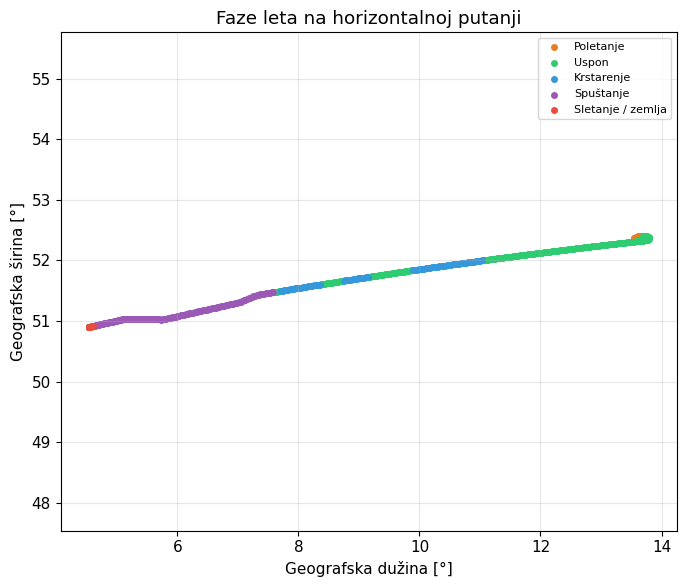

In [14]:
if has_position:
    plt.figure(figsize=(7, 6))
    for phase, color in colors.items():
        m = phases == phase
        if m.any():
            plt.scatter(longitude[m], latitude[m], s=16, color=color, label=phase)
    plt.xlabel("Geografska dužina [°]"); plt.ylabel("Geografska širina [°]")
    plt.title("Faze leta na horizontalnoj putanji")
    plt.legend(fontsize=8); plt.axis("equal"); plt.tight_layout(); plt.show()
else:
    print("Let nema poziciju -> mapa faza se preskače.")

## 5. Rezultati, ograničenja i zaključak

**Rezultati.** Iz 24 sata OpenSky podataka izdvojen je skup potpunih letova zadovoljavajućeg kvaliteta. Kombinovanjem tri veličine određuju se faze leta: znak vertikalne brzine razdvaja uspon i spuštanje, visina razdvaja krstarenje od niskog prilaza, a brzina i `onground` pomažu kod poletanja i sletanja. Agregatno poređenje na 100 nasumičnih letova (odeljak 3.5) pokazuje da Butterworth daje najmanju prosečnu grešku na visini i brzini i pobeđuje u velikoj većini letova (~80%); uz najravniji propusni opseg bez talasanja i bez DC pomeraja, izabran je za klasifikaciju.

**Ograničenja.**

- Pragovi faza zavise od tipa aviona i definicije faze; relativni pragovi ublažavaju, ali ne uklanjaju, tu zavisnost.
- `onground` zastavica je u skupu retka, pa se sletanje uglavnom prepoznaje iz visine; početak zaleta po pisti ne mora biti zabeležen.
- Resemplovanje interpolira preko praznina; zato su odbačeni letovi sa velikim rupama (> 600 s) i niskom pokrivenošću (< 80%).
- Nula-fazno filtriranje koristi buduće odbirke, pa nije primenljivo u realnom vremenu; tada bi se koristio kauzalni filtar uz kompenzaciju kašnjenja.

**Zaključak.** Težište rada je na obradi realnih, nesavršenih ADS-B podataka: čišćenju (duplikati, impulsni ispadi, praznine), kontroli kvaliteta i resemplovanju, a zatim na spektralno opravdanom niskopropusnom filtriranju i pravilskom određivanju faza. Rezultat verno prati fizički oblik putanje leta.

## Reference

1. OpenSky Network — [Scientific Datasets](https://opensky-network.org/data/scientific).
2. OpenSky Network — [State Vector Dataset README](https://opensky-network.org/datasets/states/README.txt).
3. SciPy `scipy.signal`: `butter`, `cheby1`, `firwin`, `kaiserord`, `freqz`, `group_delay`, `filtfilt`.
4. A. V. Oppenheim, R. W. Schafer — *Discrete-Time Signal Processing*, Pearson.